## Project Overview

Healthcare organizations collect patient information from many different systems, including:

- Electronic Health Records (EHR)
- Laboratory Information Systems (LIS)
- Pharmacy Systems
- Billing Systems
- Imaging Systems

Before this data can be used for dashboards, clinical reporting, or machine learning models, it must first be checked for quality issues.

Common problems include:

- Missing patient information
- Duplicate patient records
- Invalid clinical values
- Incorrect data types
- Patient identifiers that violate HIPAA

In this notebook, we will simulate the work of a Healthcare Data Analyst by exploring a healthcare dataset, identifying common data quality issues, and preparing the data for downstream analytics.

This project demonstrates a simplified version of the preprocessing pipeline commonly used in hospitals before data is loaded into a Data Warehouse or Data Lakehouse.

By the end of this notebook we will learn how to:

✔ Load healthcare data

✔ Explore healthcare datasets

✔ Understand each column

✔ Detect missing values

✔ Detect duplicate patients

✔ Validate clinical values

✔ Apply HIPAA de-identification

✔ Produce an analytics-ready dataset

Throughout this notebook, every code block is explained in beginner-friendly language, along with real hospital scenarios showing why each step matters.

Real Hospital Scenario
## 🏥 Real Hospital Scenario

Imagine you have just joined **Horizon One Medical Center** as a Healthcare Data Analyst.

Every day, patient information flows from multiple departments:

Patient Registration
        ↓
Electronic Health Record (EHR)
        ↓
Laboratory System
        ↓
Pharmacy System
        ↓
Billing System
        ↓
Data Warehouse
        ↓
Dashboards & AI Models

Before hospital leadership can trust dashboards or AI predictions, the data must be carefully validated.

Your job is to make sure the healthcare data is:

- Complete
- Accurate
- Consistent
- Valid
- Privacy Protected

This notebook follows that exact workflow.

Step 1 — Import Required Libraries

We import external libraries that help us:

- Read CSV files
- Explore datasets
- Clean data
- Detect data quality issues


In [1]:
import pandas as pd
import numpy as np

Step 2 — Load the Healthcare Dataset

Healthcare data is usually stored in files such as:

- CSV
- Excel
- SQL Database
- Data Warehouse
- Data Lake

For this project, we will load a CSV file into a Pandas DataFrame.

Once loaded, we can begin exploring the patient records.

In [2]:
df = pd.read_csv("clinical_data_quality_lab_dataset_exercises.csv")

pd.read_csv() reads a CSV file and converts it into a DataFrame.

df is simply a variable name that stores our healthcare dataset.

Think of it like:

CSV File

↓

read_csv()

↓

DataFrame (df)

Code Pattern
Read File

↓

Store Inside Variable

↓

Use Variable for Analysis

Step 3 — Explore the Healthcare Dataset


Step 3 — Explore the Healthcare Dataset
# 🏥 Step 3: Explore the Healthcare Dataset

## Why are we doing this?

Imagine your hospital gives you a new dataset extracted from the Electronic Health Record (EHR).

Before cleaning the data, building dashboards, or training AI models, you first need to understand what the dataset contains.

This process is called **Data Exploration**.

During this step, we answer questions such as:

- How many patient records are there?
- How many variables (columns) are available?
- What information does each column contain?
- Are the data types correct?
- Does anything look suspicious?

Healthcare data should never be analyzed before understanding its structure.

tep 3.1 — Display the First Few Records
🏥 Why do we use this?
## 📊 View the First Five Records

### What does this code do?

The `head()` function displays the first few rows of the dataset.

This gives us a quick preview of the patient records without opening the entire file.

It helps us understand:

- What columns exist
- What values look like
- Whether the dataset loaded correctly

In [3]:
df.head(10)

,patient_id,patient_name,date_of_birth,visit_date,heart_rate,systolic_bp
0,P0090,Patient_P0090,1995-06-17,2023-02-26,92,127.0
1,P0120,Patient_P0120,1987-01-18,2023-02-08,106,280.0
2,P0384,Patient_P0384,1989-01-12,2023-02-04,72,112.0
3,P0088,Patient_P0088,1944-04-20,2023-02-02,78,110.0
4,P0100,Patient_P0100,1959-10-13,2023-02-21,59,106.0
5,P0064,Patient_P0064,1955-01-22,2023-02-01,71,115.0
6,P0444,Patient_P0444,1941-09-02,2023-02-25,91,135.0
7,P0064,Patient_P0064,1978-03-10,2023-02-16,90,141.0
8,P0233,Patient_P0233,1952-08-11,2023-02-03,89,138.0
9,P0426,Patient_P0426,1952-11-06,2023-02-07,82,100.0


returns the first 5 rows by default.

You can also specify another number:

df.head(10)

shows the first 10 patients.

🧠 Code Pattern
DataFrame

↓

head()

↓

Quick Preview
🏥 Real Hospital Scenario

Suppose the hospital exports yesterday's Emergency Department visits.

Before doing anything else, you preview the first few patients to confirm:

Patient IDs exist
Visit dates look correct
Vital signs were imported

Instead of reading thousands of rows manually, head() gives an instant snapshot

Step 3.2 — Check Dataset Size
🏥 Why do we use this?
## How Large is the Dataset?

Before analysis, we want to know:

- How many patient records do we have?
- How many variables were collected?

This helps us estimate the scope of the analysis.

In [4]:

df.shape


(2120, 6)

Step 3.3 — View Column Names
🏥 Why do we use this?
## What Variables are Available?

Each column represents one type of healthcare information.

Examples include:

- Patient ID
- Heart Rate
- Blood Pressure
- Visit Date

Before analysis, we need to know exactly what variables are available.

In [5]:
df.columns

Index(['patient_id', 'patient_name', 'date_of_birth', 'visit_date',
       'heart_rate', 'systolic_bp'],
      dtype='object')

Step 3.4 — Check Data Types
🏥 Why do we use this?
## Understanding Data Types

Each column has a specific data type.

Examples:

- Patient Name → Text
- Visit Date → Date
- Heart Rate → Number

Knowing the data type is important because incorrect data types can cause errors during analy

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2120 entries, 0 to 2119
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   patient_id     2120 non-null   object 
 1   patient_name   2120 non-null   object 
 2   date_of_birth  2120 non-null   object 
 3   visit_date     2120 non-null   object 
 4   heart_rate     2120 non-null   int64  
 5   systolic_bp    1954 non-null   float64
dtypes: float64(1), int64(1), object(4)
memory usage: 99.5+ KB


e Visit Date is stored as text instead of a date.

This can cause problems such as:

❌ Incorrect monthly reports

❌ Wrong patient timelines

❌ AI models using dates incorrectly

Checking data types early helps prevent these issues.

Step 3.5 — Generate Summary Statistics
🏥 Why do we use this?
## Summary Statistics

Now we examine the numerical variables.

For example:

- Average Heart Rate
- Lowest Blood Pressure
- Highest Blood Pressure

This helps identify unusual values before cleaning the data.

In [7]:
df.describe()

,heart_rate,systolic_bp
count,2120.000000,1954.000000
mean,79.258491,134.152508
std,35.600547,35.629246
min,-20.000000,67.000000
25%,67.000000,116.000000
50%,77.000000,129.000000
75%,88.000000,141.000000
max,290.000000,320.000000


Real Hospital Scenario

Suppose the output shows:

Maximum Heart Rate = 420 bpm

A heart rate of 420 bpm is biologically impossible for a living patient.

This immediately tells the data analyst:

Possible data entry error
Device malfunction
Incorrect unit conversion

This value should be investigated before building dashboards or AI models.

How This Affects Dashboards

Imagine the hospital dashboard shows:

Average Heart Rate = 115 bpm

Why?

Because one patient's heart rate was mistakenly entered as:

850 bpm

instead of:

85 bpm

One incorrect value can significantly distort the average, leading hospital staff to believe patients are sicker than they actually are.

How This Affects AI Models

Suppose we're building a Sepsis Prediction Model.

One of the input features is:

Heart Rate

If the dataset contains impossible values such as:

850 bpm

the AI model may learn incorrect patterns, resulting in poor predictions.

This is why data exploration always comes before data cleaning.

Step 4 — Healthcare Data Quality Assessment
# 🏥 Step 4: Healthcare Data Quality Assessment

## Why are we doing this?

Healthcare data is collected by many people and systems:

- Receptionists
- Nurses
- Doctors
- Laboratory Systems
- Medical Devices
- Pharmacy Systems

Because data comes from multiple sources, errors are inevitable.

Some common data quality issues include:

- Missing values
- Duplicate patients
- Impossible vital signs
- Incorrect dates
- Invalid patient identifiers

Before data is used for dashboards or machine learning, analysts perform data quality checks.

This process helps ensure that healthcare decisions are based on reliable information.

Real Hospital Scenario
Imagine your hospital wants to build a Sepsis Prediction Model.

The model requires:

• Heart Rate
• Blood Pressure
• Temperature
• Respiratory Rate

If any of these values are missing or incorrect, the model may underestimate a patient's risk.

Similarly, hospital dashboards depend on complete and accurate data.

Therefore, checking data quality is one of the first responsibilities of a Healthcare Data Analyst.

Step 4.1 — Check Missing Values
Why do we do this?
## What are Missing Values?

A missing value means that information was expected but was never recorded.

Examples:

• Nurse forgot to record Heart Rate
• Blood Pressure monitor disconnected
• Lab test was never completed

Missing values are important because they can affect:

- Dashboard accuracy
- Statistical analysis
- AI model performance

In [8]:
# Count missing values in each column
df.isnull().sum()

,0
patient_id,0
patient_name,0
date_of_birth,0
visit_date,0
heart_rate,0
systolic_bp,166


What this code does

isnull()

↓

Checks every cell.

sum()

↓

Counts how many missing values exist.

Code Pattern 🧠
DataFrame

↓

Check Missing Values

↓

Count Missing Values

↓

Review Results

Real Hospital Example

Suppose your Sepsis AI model needs:

Heart Rate
Blood Pressure

Patient:

Heart Rate = Missing
Blood Pressure = 120

The AI receives incomplete information.

Instead of predicting:

High Risk

it may predict

Low Risk

because an important clinical signal is missing.

Dashboard Impact

Hospital dashboard:

Average Heart Rate

If many heart rates are missing,

the dashboard average becomes inaccurate.

Hospital leadership may think patients are healthier than they actually are.

Step 4.2 — Calculate Missing Percentage

Hospitals usually care about the percentage of missing data, not just the count.

Knowing that 4 heart rates are missing is useful.

Knowing that **40%** are missing is much more meaningful.

Hospitals often create dashboards showing missing percentages for critical variables.

In [9]:
missing_percentage = df.isnull().mean() * 100

missing_percentage.round(2)

,0
patient_id,0.00
patient_name,0.00
date_of_birth,0.00
visit_date,0.00
heart_rate,0.00
systolic_bp,7.83


Find Missing

↓

Calculate Mean

↓

Multiply ×100

↓

Percentage Missing

ashboard:

Variable	Missing %
Heart Rate	2%
Blood Pressure	1%
Temperature	25%

Immediately the hospital notices:

Temperature Collection Problem

Now the analyst investigates:

Patient

↓

Bedside Monitor

↓

HL7/FHIR Interface

↓

EHR

↓

Data Warehouse

Where is the problem?

Step 4.3 — Check for Duplicate Patients
Why do we do this?
Sometimes the same patient accidentally receives two different patient IDs.

This may happen because:

- Name misspelled
- Registration error
- Multiple hospital systems

Duplicate patients are a major healthcare data quality issue.

In [11]:
df["patient_id"].duplicated().sum()

np.int64(1674)

What this code does

Looks at every Patient ID.

Checks whether it already appeared before.

Counts duplicates.

Code Pattern
Select Column

↓

duplicated()

↓

sum()

↓

Number of Duplicates

Real Hospital Example

Actual patient:

Patient ID = 1025

appears twice.

Dashboard sees:

2 patients

Reality:

1 patient
📊 Dashboard Impact

Hospital wants to count diabetic patients.

Reality:

500 Patients

Dashboard:

505 Patients

because five patients were duplicated.

Disease prevalence becomes incorrect.

Step 4.4 — Display Duplicate Records

Finding duplicates is useful.

Seeing them is even better

In [12]:
duplicates = df[df["patient_id"].duplicated()]

duplicates

,patient_id,patient_name,date_of_birth,visit_date,heart_rate,systolic_bp
7,P0064,Patient_P0064,1978-03-10,2023-02-16,90,141.0
21,P0235,Patient_P0235,1973-12-08,2023-02-21,91,137.0
24,P0444,Patient_P0444,1989-01-23,2023-02-12,62,160.0
27,P0123,Patient_P0123,1968-02-06,2023-02-11,66,109.0
49,P0345,Patient_P0345,1949-12-22,2023-02-15,65,100.0
...,...,...,...,...,...,...
2115,P0085,Patient_P0085,1999-04-12,2023-02-27,78,98.0
2116,P0043,Patient_P0043,1957-12-23,2023-02-21,70,138.0
2117,P0266,Patient_P0266,1969-11-23,2023-02-01,79,112.0
2118,P0440,Patient_P0440,1953-02-14,2023-02-08,106,123.0


What this code does

Creates a new table containing only duplicate patient records.

This allows analysts to manually investigate the problem.

Code Pattern
Find Duplicate Rows

↓

Store Results

↓

Display Records
🏥 Real Hospital Example

You discover:

Patient ID	Name
1025	John Smith
1025	John Smith

Now you ask:

Was this:

Duplicate registration?

or

Legitimate repeat visit?

This investigation prevents incorrect reporting.

Step 4.5 — Count Unique Patients

Hospitals usually care about unique patients, not total rows.

In [13]:
df["patient_id"].nunique()

446

What this code does

Counts unique Patient IDs.

Unlike count(), duplicates are ignored.

Code Pattern
Column

↓

nunique()

↓

Unique Values

Real Hospital Example

Dataset:

Rows = 520

Unique patients:

500

This tells us:

Twenty rows belong to repeat or duplicate patient records.

How This Affects AI Models

Suppose we're training a model to predict:

Hospital Readmission

If duplicate patients remain:

Patient A appears twice.

The AI believes:

Two different patients

instead of

One patient

This biases the model and can make performance metrics look artificially better or worse.

How This Affects Hospital Dashboards

Without quality checks:

Missing Values

↓

Wrong Average Heart Rate

↓

Incorrect Patient Counts

↓

Duplicate Disease Cases

↓

Misleading Hospital Dashboard

With quality checks:

Clean Dataset

↓

Reliable KPIs

↓

Accurate Reports

↓

Better Clinical Decisions

Section 5 — Data Quality Assessment

Why are we doing this?

Before cleaning a healthcare dataset, we first need to understand how good or bad the data is.

Imagine a hospital wants to build a Sepsis Prediction Model.

If:

Temperature is missing
Heart Rate has impossible values
Blood Pressure contains duplicates
Patient IDs are repeated

the AI model may produce incorrect predictions.

Instead of cleaning blindly, we first inspect the dataset.

This process is called Data Quality Assessment.

Real Hospital Scenario

A hospital wants to predict which patients are likely to develop sepsis.

The model requires:

Temperature
Heart Rate
Respiratory Rate
Blood Pressure

Suppose:

Temperature

98.6
99.1
NULL
NULL

If many temperatures are missing,

the model may underestimate patient risk.

Before building the model,

the data team first measures

missing values
duplicates
invalid values
inconsistent formatting

Display Basic Dataset Information
What does this code do?

This code prints:

number of rows
number of columns
column names
data types

This gives us a quick overview of the dataset.

Why do we use it?

Healthcare datasets often contain

numeric columns
dates
categorical variables
identifiers

Knowing the datatype helps us decide how each variable should be cleaned.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2120 entries, 0 to 2119
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   patient_id     2120 non-null   object 
 1   patient_name   2120 non-null   object 
 2   date_of_birth  2120 non-null   object 
 3   visit_date     2120 non-null   object 
 4   heart_rate     2120 non-null   int64  
 5   systolic_bp    1954 non-null   float64
dtypes: float64(1), int64(1), object(4)
memory usage: 99.5+ KB


Statistical Summary
What does this code do?

This summarizes every numeric column.

It calculates

mean
minimum
maximum
quartiles
standard deviation

Statistical Summary
What does this code do?

This summarizes every numeric column.

It calculates

mean
minimum
maximum
quartiles
standard deviation

In [15]:
df.describe()

,heart_rate,systolic_bp
count,2120.000000,1954.000000
mean,79.258491,134.152508
std,35.600547,35.629246
min,-20.000000,67.000000
25%,67.000000,116.000000
50%,77.000000,129.000000
75%,88.000000,141.000000
max,290.000000,320.000000


Why do we use it?

Suppose Temperature contains

36
37
38
250

250°C is impossible.

The summary immediately shows

Max Temperature = 250

Now we know something is wrong.

Hospital Example

Suppose Heart Rate

80
75
91
850

Human heart rate cannot be

850 bpm.

This is probably

data entry error

or

device error

In [16]:
df.describe()

,heart_rate,systolic_bp
count,2120.000000,1954.000000
mean,79.258491,134.152508
std,35.600547,35.629246
min,-20.000000,67.000000
25%,67.000000,116.000000
50%,77.000000,129.000000
75%,88.000000,141.000000
max,290.000000,320.000000


Numeric Columns

↓

Find impossible values

↓

Find unusual ranges

↓

Investigate

Check Missing Values
What does this code do?

This counts missing values in every column.

In [17]:
df.isnull().sum()

,0
patient_id,0
patient_name,0
date_of_birth,0
visit_date,0
heart_rate,0
systolic_bp,166


Why do we use it?

Missing values are one of the biggest problems in healthcare.

Example

Temperature

98.7
99.2
NULL
NULL

If Temperature is missing,

Sepsis Prediction

may underestimate patient risk.

Missing Value Percentage
What does this code do?

Instead of counting,

this calculates

the percentage of missing values.

In [18]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent.sort_values(ascending=False)

,0
systolic_bp,7.830189
patient_id,0.000000
patient_name,0.000000
date_of_birth,0.000000
visit_date,0.000000
heart_rate,0.000000


Why do we use it?

Suppose

Respiratory Rate

Missing = 500 rows

Is that bad?

Depends on dataset size.

If

500 / 100000

only

0.5%

Not terrible.

But

500 / 600

means

83%

Very serious.

Hospital Dashboard Example

A Data Quality Dashboard may show

Variable	Missing %
Temperature	1%
Heart Rate	0%
Respiratory Rate	38%
Blood Pressure	4%

Immediately,

the Data Engineer knows

Respiratory Rate interface needs investigation.

Missing Count

↓

Convert to %

↓

Rank columns

↓

Prioritize cleaning

Check Duplicate Records
What does this code do?

Counts duplicated rows.

In [19]:
df.duplicated().sum()

np.int64(120)

Real Hospital Example

Patient

John Smith

appears twice because

Registration Desk created

two Medical Record Numbers.

Analytics now sees

John Smith

John Smith

instead of

one patient.

Effects

❌ Readmission Rate changes

❌ Disease prevalence changes

❌ Patient counts increase

View Duplicate Records
What does this code do?

Displays duplicate rows so we can inspect them.

In [20]:
duplicates = df[df.duplicated()]

duplicates.head()

,patient_id,patient_name,date_of_birth,visit_date,heart_rate,systolic_bp
76,P0302,Patient_P0302,2000-09-17,2023-02-12,80,141.0
85,P0448,Patient_P0448,1979-03-12,2023-02-05,71,112.0
183,P0425,Patient_P0425,1981-07-19,2023-02-16,69,320.0
206,P0347,Patient_P0347,1979-04-27,2023-02-07,99,113.0
230,P0065,Patient_P0065,1958-06-15,2023-02-09,102,111.0


Why do we use it?

Never delete duplicates immediately.

Sometimes they represent

repeated visits
follow-up appointments
multiple lab tests

instead of errors.

Always inspect first.

Real Hospital Example

Patient

MRN 1001

Visit 1

Jan 1

and

MRN 1001

Visit 2

Jan 15

These are not duplicates.

They are

two legitimate encounters.

Pattern to Remember
duplicates = df[df.duplicated()]

Pattern

Find

↓

Inspect

↓

Understand

↓

Then clean

Section 6 — Clinical Data Validation

Why are we doing this?

Not every value stored in the EHR is correct.

Sometimes errors happen because of:

Manual typing mistakes
Faulty bedside monitors
HL7/FHIR transmission problems
Unit conversion errors
Device malfunctions

A value may exist, but it may be medically impossible.

Before using healthcare data for analytics or machine learning, we must validate that clinical measurements fall within realistic human ranges.

dentify Numeric Columns
What does this code do?

This code lists all columns containing numeric data.

These are usually the columns we validate.

Why do we use it?

Healthcare datasets contain:

Patient IDs
Dates
Names
Vital Signs
Laboratory Values

Only numeric clinical variables should be checked for impossible values.

In [21]:
df.select_dtypes(include="number").columns

Index(['heart_rate', 'systolic_bp'], dtype='object')

Check Heart Rate Range
What does this code do?

Displays the smallest and largest heart rate values.

In [22]:
print("Minimum Heart Rate:", df["heart_rate"].min())
print("Maximum Heart Rate:", df["heart_rate"].max())

Minimum Heart Rate: -20
Maximum Heart Rate: 290


Why do we use it?

Heart Rate has known biological limits.

Typical adults:

Resting

60–100 bpm

Hospital patients may range

30–220 bpm

If we see

800 bpm

it is almost certainly an error.

Hospital Example

850 bpm

↓

Impossible

↓

Investigate

Possible causes:

Extra zero typed
Device malfunction
HL7 interface error

Find Impossible Heart Rates
What does this code do?

Shows patients whose heart rate is outside a realistic range.

In [23]:
invalid_hr = df[(df["heart_rate"] < 30) | (df["heart_rate"] > 220)]

invalid_hr

,patient_id,patient_name,date_of_birth,visit_date,heart_rate,systolic_bp
16,P0018,Patient_P0018,2000-12-25,2023-02-27,0,102.0
19,P0235,Patient_P0235,1963-03-13,2023-02-03,-20,141.0
47,P0345,Patient_P0345,1980-09-27,2023-02-15,290,129.0
90,P0355,Patient_P0355,1949-04-21,2023-02-28,0,119.0
116,P0091,Patient_P0091,1947-06-08,2023-02-10,0,129.0
...,...,...,...,...,...,...
2003,P0070,Patient_P0070,1977-07-07,2023-02-16,-20,141.0
2071,P0124,Patient_P0124,1969-08-26,2023-02-04,0,140.0
2072,P0228,Patient_P0228,1978-03-25,2023-02-11,-20,112.0
2093,P0429,Patient_P0429,1969-08-27,2023-02-02,-20,320.0


Why do we use it?

Instead of checking every patient manually,

we automatically identify suspicious records.

Hospital Example

| Patient |  HR |
| ------- | --: |
| A       |  80 |
| B       |  76 |
| C       |  15 |
| D       | 310 |
Results

Patient C

↓

Too Low

Patient D

↓

Too High

Both require investigation.

Pattern to Remember
df[(column < minimum) | (column > maximum)]

Pattern

Choose Variable

↓

Define Valid Range

↓

Filter Invalid Records

↓

Review

Validate Blood Pressure
What does this code do?

Looks for unrealistic blood pressure values.

In [24]:
invalid_bp = df[
    (df["systolic_bp"] < 50) |
    (df["systolic_bp"] > 300)
]

invalid_bp

,patient_id,patient_name,date_of_birth,visit_date,heart_rate,systolic_bp
20,P0123,Patient_P0123,1954-03-14,2023-02-20,70,320.0
144,P0425,Patient_P0425,1981-07-19,2023-02-16,69,320.0
181,P0317,Patient_P0317,1950-02-01,2023-02-05,63,320.0
183,P0425,Patient_P0425,1981-07-19,2023-02-16,69,320.0
310,P0235,Patient_P0235,1955-07-04,2023-02-21,90,320.0
313,P0117,Patient_P0117,1979-08-07,2023-02-22,66,320.0
324,P0259,Patient_P0259,1993-04-08,2023-02-05,104,320.0
368,P0191,Patient_P0191,1976-05-20,2023-02-09,70,320.0
427,P0122,Patient_P0122,1941-02-08,2023-02-06,73,320.0
578,P0009,Patient_P0009,2000-09-16,2023-02-02,61,320.0


Why do we use it?

A systolic blood pressure of

900 mmHg

cannot happen.

This is likely

typing error
monitor failure
interface issue

Real Hospital Example

Suppose bedside monitor accidentally sends

1200

instead of

120

The value travels

Monitor

↓

HL7

↓

EHR

↓

Data Warehouse

↓

Dashboard

↓

AI Model

Without validation,

every downstream system now contains bad data.

Pattern to Remember
df[(column < lower_limit) | (column > upper_limit)]

Count Invalid Records
What does this code do?

Counts how many invalid values exist.

Count Invalid Records
What does this code do?

Counts how many invalid values exist.

In [25]:
len(invalid_hr)

94

Why do we use it?

Hospitals monitor data quality using metrics.

| Variable       | Invalid Values |
| -------------- | -------------: |
| Heart Rate     |             12 |
| Blood Pressure |              3 |
| Temperature    |              0 |


ualize Outliers
What does this code do?

Creates a boxplot to visualize unusual values.

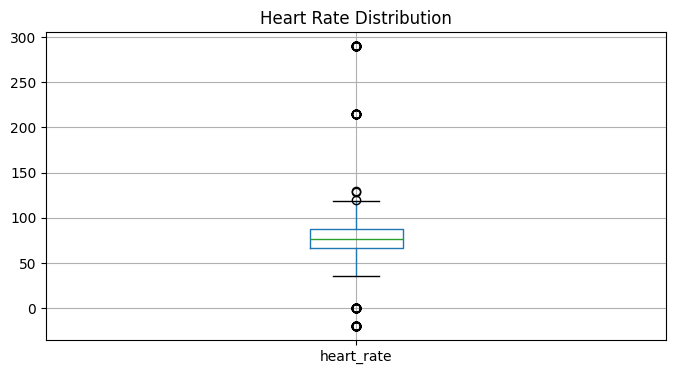

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

df.boxplot(column="heart_rate")

plt.title("Heart Rate Distribution")

plt.show()

Pattern to Remember
df.boxplot(column="column_name")

Pattern

Numeric Variable

↓

Visualize Distribution

↓

Identify Outliers

↓

Investigate

How This Affects Dashboards and AI Models
📈 Hospital Dashboard

Suppose one faulty monitor records:

Heart Rate = 999 bpm

The dashboard calculates:

How This Affects Dashboards and AI Models
📈 Hospital Dashboard

Suppose one faulty monitor records:

Heart Rate = 999 bpm

The dashboard calculates:

Metric	Correct	With Error
Average Heart Rate	82	105

Leadership now believes patients are becoming more unstable.

The dashboard isn't broken—the data is.

🤖 AI Model

Suppose you're training a sepsis prediction model.

Most patients:

Heart Rate

70–130

One patient:

999

The AI may incorrectly learn that extremely high heart rates are common, reducing model accuracy and generalizability.

Why Healthcare Analysts Do This

Clinical validation ensures that healthcare data reflects real patient physiology, not data entry mistakes or system failures.

Without this step:

❌ Dashboards become misleading.
❌ AI models learn from incorrect data.
❌ Quality reports become unreliable.
❌ Clinical decisions may be based on faulty information.

Section 7 — Data Cleaning and Normalization

Why are we doing this?

After validating the data, we now fix common problems.

Healthcare data comes from many systems:

EHR
Laboratory
Pharmacy
Radiology
Billing

Each system may record data differently.


| System   | Stores Gender |
| -------- | ------------- |
| EHR      | Male          |
| Lab      | M             |
| Billing  | male          |
| Research | MALE          |
Although these all mean the same thing, a computer treats them as different values.

Cleaning and normalization make the dataset consistent.

Real Hospital Scenario

A hospital wants to count the number of male patients.

Raw data:
| Patient | Gender |
| ------- | ------ |
| John    | Male   |
| Alex    | M      |
| David   | male   |
| Chris   | MALE   |
Dashboard result:

Male = 1

M = 1

male = 1

MALE = 1

Remove Duplicate Records
What does this code do?

This removes duplicate rows from the dataset.

In [28]:
df = df.drop_duplicates()

HL7 messages were processed twice.
Data was imported twice.
The same patient was accidentally entered twice.

Removing true duplicates improves data quality.

Note: In real hospitals, always investigate duplicates first. Some repeated rows represent legitimate repeat visits or lab tests and should not be remove

🏥 Hospital Example

Before cleaning

| Patient | Visit |
| ------- | ----- |
| John    | ER    |
| John    | ER    |

After cleaning
| Patient | Visit |
| ------- | ----- |
| John    | ER    |


Convert Date Columns
What does this code do?

Converts text into proper datetime format.

In [32]:
df["visit_date"] = pd.to_datetime(df["visit_date"])

Why do we use it?

Many datasets store dates as plain text.

Example:

01/05/2024

Computers cannot easily calculate:

Length of stay
Readmission within 30 days
Patient age
Time between visits

until the column is converted into a datetime type

🏥 Hospital Example

Without conversion

"01/02/2024"

"15/02/2024"

are just strings.

After conversion

Pandas understands them as dates and allows date calculations.

ill Missing Values
What does this code do?

Replaces missing values with a chosen value.

df["temperature"] = df["temperature"].fillna(df["temperature"].median())

df["temperature"] = df["temperature"].fillna(df["temperature"].median())

Why do we use it?

Some AI algorithms cannot work with missing values.

Instead of deleting many patients, we sometimes replace missing values with the median.

Important: In healthcare, never fill missing values automatically without understanding why they are missing. Sometimes a missing lab test means it was never ordered, which is clinically meaningful.

Rename Columns
What does this code do?

Makes column names consistent and easier to use

In [33]:
df.columns = (
    df.columns
      .str.lower()
      .str.strip()
      .str.replace(" ", "_")
)

Why do we use it?

Before

Patient ID

Admission Date

Heart Rate

After

patient_id

admission_date

heart_rate

This makes coding easier and avoids typing errors.

Verify the Cleaned Dataset
What does this code do?

Displays the first few cleaned rows.

In [34]:
df.head()

,patient_id,patient_name,date_of_birth,visit_date,heart_rate,systolic_bp
0,P0090,Patient_P0090,1995-06-17,2023-02-26,92,127.0
1,P0120,Patient_P0120,1987-01-18,2023-02-08,106,280.0
2,P0384,Patient_P0384,1989-01-12,2023-02-04,72,112.0
3,P0088,Patient_P0088,1944-04-20,2023-02-02,78,110.0
4,P0100,Patient_P0100,1959-10-13,2023-02-21,59,106.0


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 0 to 2119
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   patient_id     2000 non-null   object        
 1   patient_name   2000 non-null   object        
 2   date_of_birth  2000 non-null   object        
 3   visit_date     2000 non-null   datetime64[ns]
 4   heart_rate     2000 non-null   int64         
 5   systolic_bp    1842 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 173.9+ KB


Why do we use it?

Cleaning can accidentally introduce mistakes.

Always verify:

Missing values
Data types
Column names
Standardized text
Duplicate removal

HIPAA De-identification
📖 Why are we doing this?

Healthcare datasets contain Protected Health Information (PHI).

Examples include:

Patient Name
Medical Record Number (MRN)
Address
Phone Number
Email
Social Security Number
Date of Birth

Hospitals cannot share these identifiers for research or AI projects.

Before analysts or data scientists receive the data, hospitals perform de-identification.

De-identification removes or transforms patient identifiers while preserving the clinical information needed for analysis.

eal Hospital Scenario

Imagine your hospital wants to build an AI model that predicts 30-day readmission.

The data science team does not need to know the patient's name.

They only need information like:

Age
Diagnosis
Laboratory Results
Medications
Length of Stay

Therefore, before the dataset leaves the hospital's secure environment, all identifying information is removed or masked.

View PHI Columns
What does this code do?

This displays the columns that contain personally identifiable information.

In [37]:
phi_columns = [
    "patient_name",
    "patient_id",
    "date_of_birth"
]

df[phi_columns].head()

,patient_name,patient_id,date_of_birth
0,Patient_P0090,P0090,1995-06-17
1,Patient_P0120,P0120,1987-01-18
2,Patient_P0384,P0384,1989-01-12
3,Patient_P0088,P0088,1944-04-20
4,Patient_P0100,P0100,1959-10-13


Why do we use it?

Before removing PHI, we first identify where it exists.

Think of this as creating an inventory of sensitive information

| Patient Name | DOB        | Phone    |
| ------------ | ---------- | -------- |
| John Smith   | 1982-05-01 | 555-1234 |
Pattern to Remember
Select Sensitive Columns

↓

Review

↓

Decide De-identification Strategy

Remove Direct Identifiers
What does this code do?

Removes columns that directly identify a patient.

In [39]:
df = df.drop(
    columns=[
        "patient_name",
        "patient_id",
        "date_of_birth"
    ]
)

Why do we use it?

These columns are direct identifiers.

Keeping them is unnecessary for most analytics projects.

Removing them greatly reduces privacy risk.

Mask Medical Record Number (MRN)
What does this code do?

Instead of deleting the patient ID completely,

we replace it with an anonymous identifier.

In [ ]:
df["patient_id"] = (
    "PAT_"
    + df.index.astype(str)
)

Why do we use it?

Researchers still need a way to distinguish patients.

But they don't need the hospital's real MRN.

🏥 Hospital Example

Before

MRN
100458

After

Patient ID
PAT_001

Now

same patient can still be tracked

but

hospital MRN remains hidden.

Convert Date of Birth into Age
What does this code do?

Instead of storing the exact birthday,

we calculate patient age.

In [ ]:
from datetime import datetime

current_year = datetime.now().year

df["age"] = (
    current_year -
    pd.to_datetime(df["date_of_birth"]).dt.year
)

Why do we use it?

Exact birthdays can identify patients.

Age is usually sufficient for analytics.

Verify PHI Removal
What does this code do?

Displays the cleaned dataset.

In [42]:
df.head()

,visit_date,heart_rate,systolic_bp
0,2023-02-26,92,127.0
1,2023-02-08,106,280.0
2,2023-02-04,72,112.0
3,2023-02-02,78,110.0
4,2023-02-21,59,106.0


Why do we use it?

Always verify that:

Patient names are gone
Phone numbers are gone
Addresses are gone
DOB is removed
Clinical information remains

Pattern to Remember

Check Final Dataset

↓

Confirm PHI Removed

↓

Ready for Analytics

provides two ways to de-identify data.

1. Safe Harbor (Most Common)

Remove the 18 HIPAA identifiers.

Examples:

Name
Phone
Email
Address
SSN
MRN

This is simple and widely used.

2. Expert Determination

A privacy expert evaluates the dataset and decides whether the risk of identifying a patient is very small, even if some information (such as age or dates) is retained.

Hospitals often use this method for research datasets.

🏥 Direct Identifiers vs Quasi-identifiers
Direct Identifiers

These directly identify a patient.

Examples:

Name
MRN
SSN
Phone Number
Email

Usually removed completely.

Quasi-identifiers

These do not identify a patient by themselves but can identify someone when combined.

Examples:

Age
ZIP Code
Gender
Admission Date

These are often:

generalized,
masked,
or grouped.

Example:

Instead of:

Age = 97
ZIP = 02138

Store:

Age = 90+

ZIP = 021**

How This Affects Dashboards and AI Models
📈 Hospital Dashboard

A quality dashboard only needs aggregated data such as:

Number of diabetic patients
Average heart rate
Readmission rate

It does not need patient names.

Removing PHI does not change these metrics.

I Model

A readmission model needs:

Age
Diagnosis
Medications
Lab values
Previous admissions

It does not need:

John Smith
Phone number
Address

De-identification protects privacy while preserving the predictive value of the data.

Healthcare Data Pipeline

This is where de-identification fits in:

Patient

↓

Doctor/Nurse

↓

EHR

↓

Data Warehouse

↓

Data Cleaning

↓

Clinical Validation

↓

HIPAA De-identification   ✅

↓

Feature Engineering

↓

Dashboard

↓

Machine Learning

↓

Research

Why are we doing this?

By this point in the project, we've:

Loaded the healthcare dataset
Explored the data
Cleaned missing values
Fixed inconsistent data
Validated the dataset
Protected patient privacy using HIPAA de-identification

Before building dashboards or AI models, healthcare organizations perform one final validation to ensure the data is complete, accurate, and ready for analysis.

This final step acts as a quality checkpoint before the data is released.

🏥 Real Hospital Scenario

Imagine a hospital has finished cleaning data for 10,000 patients.

Before sending it to the analytics team, the Data Engineering team asks:

Are there still missing values?
Are patient IDs unique?
Did we accidentally remove important columns?
Is the data safe to share?
Can analysts trust this dataset?

Only after answering Yes does the dataset move to dashboards and AI models.